In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 1. Load Dataset

In [3]:
df = pd.read_csv('../data/thyroid_recurrence.csv')
df.head(5)

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


## 2. Explore the data (EDA)

In [5]:
df.describe()

,Age
count,383.000000
mean,40.866841
std,15.134494
min,15.000000
25%,29.000000
50%,37.000000
75%,51.000000
max,82.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Hx Smoking            383 non-null    str  
 4   Hx Radiothreapy       383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Pathology             383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  T                     383 non-null    str  
 12  N                     383 non-null    str  
 13  M                     383 non-null    str  
 14  Stage                 383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

In [18]:
df = df.rename(columns={
    'T':'tumors',
    'N':'nodes',
    'M':'metastasis'})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Hx Smoking            383 non-null    str  
 4   Hx Radiothreapy       383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Pathology             383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  tumors                383 non-null    str  
 12  nodes                 383 non-null    str  
 13  metastasis            383 non-null    str  
 14  Stage                 383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

In [38]:
# Make column names to be consistent and easier to work with
df.columns = df.columns.str.strip().str.lower().str.replace(' ','_')
df.columns

Index(['age', 'gender', 'smoking', 'hx_smoking', 'hx_radiothreapy',
       'thyroid_function', 'physical_examination', 'adenopathy', 'pathology',
       'focality', 'risk', 'tumors', 'nodes', 'metastasis', 'stage',
       'response', 'recurred'],
      dtype='str')

In [42]:
# Identify object columns
object_cols = list(df.dtypes[df.dtypes == 'str'].index)
object_cols

['gender',
 'smoking',
 'hx_smoking',
 'hx_radiothreapy',
 'thyroid_function',
 'physical_examination',
 'adenopathy',
 'pathology',
 'focality',
 'risk',
 'tumors',
 'nodes',
 'metastasis',
 'stage',
 'response',
 'recurred']

In [44]:
# Strip whitespace from object columns and check value counts in each features
for col in object_cols:
    df[col] = df[col].str.strip()
    print(df[col].value_counts())

gender
F    312
M     71
Name: count, dtype: int64
smoking
No     334
Yes     49
Name: count, dtype: int64
hx_smoking
No     355
Yes     28
Name: count, dtype: int64
hx_radiothreapy
No     376
Yes      7
Name: count, dtype: int64
thyroid_function
Euthyroid                      332
Clinical Hyperthyroidism        20
Subclinical Hypothyroidism      14
Clinical Hypothyroidism         12
Subclinical Hyperthyroidism      5
Name: count, dtype: int64
physical_examination
Multinodular goiter            140
Single nodular goiter-right    140
Single nodular goiter-left      89
Normal                           7
Diffuse goiter                   7
Name: count, dtype: int64
adenopathy
No           277
Right         48
Bilateral     32
Left          17
Extensive      7
Posterior      2
Name: count, dtype: int64
pathology
Papillary         287
Micropapillary     48
Follicular         28
Hurthel cell       20
Name: count, dtype: int64
focality
Uni-Focal      247
Multi-Focal    136
Name: count, dtype: 

In [59]:
object_cols

['gender',
 'smoking',
 'hx_smoking',
 'hx_radiothreapy',
 'thyroid_function',
 'physical_examination',
 'adenopathy',
 'pathology',
 'focality',
 'risk',
 'tumors',
 'nodes',
 'metastasis',
 'stage',
 'response',
 'recurred']

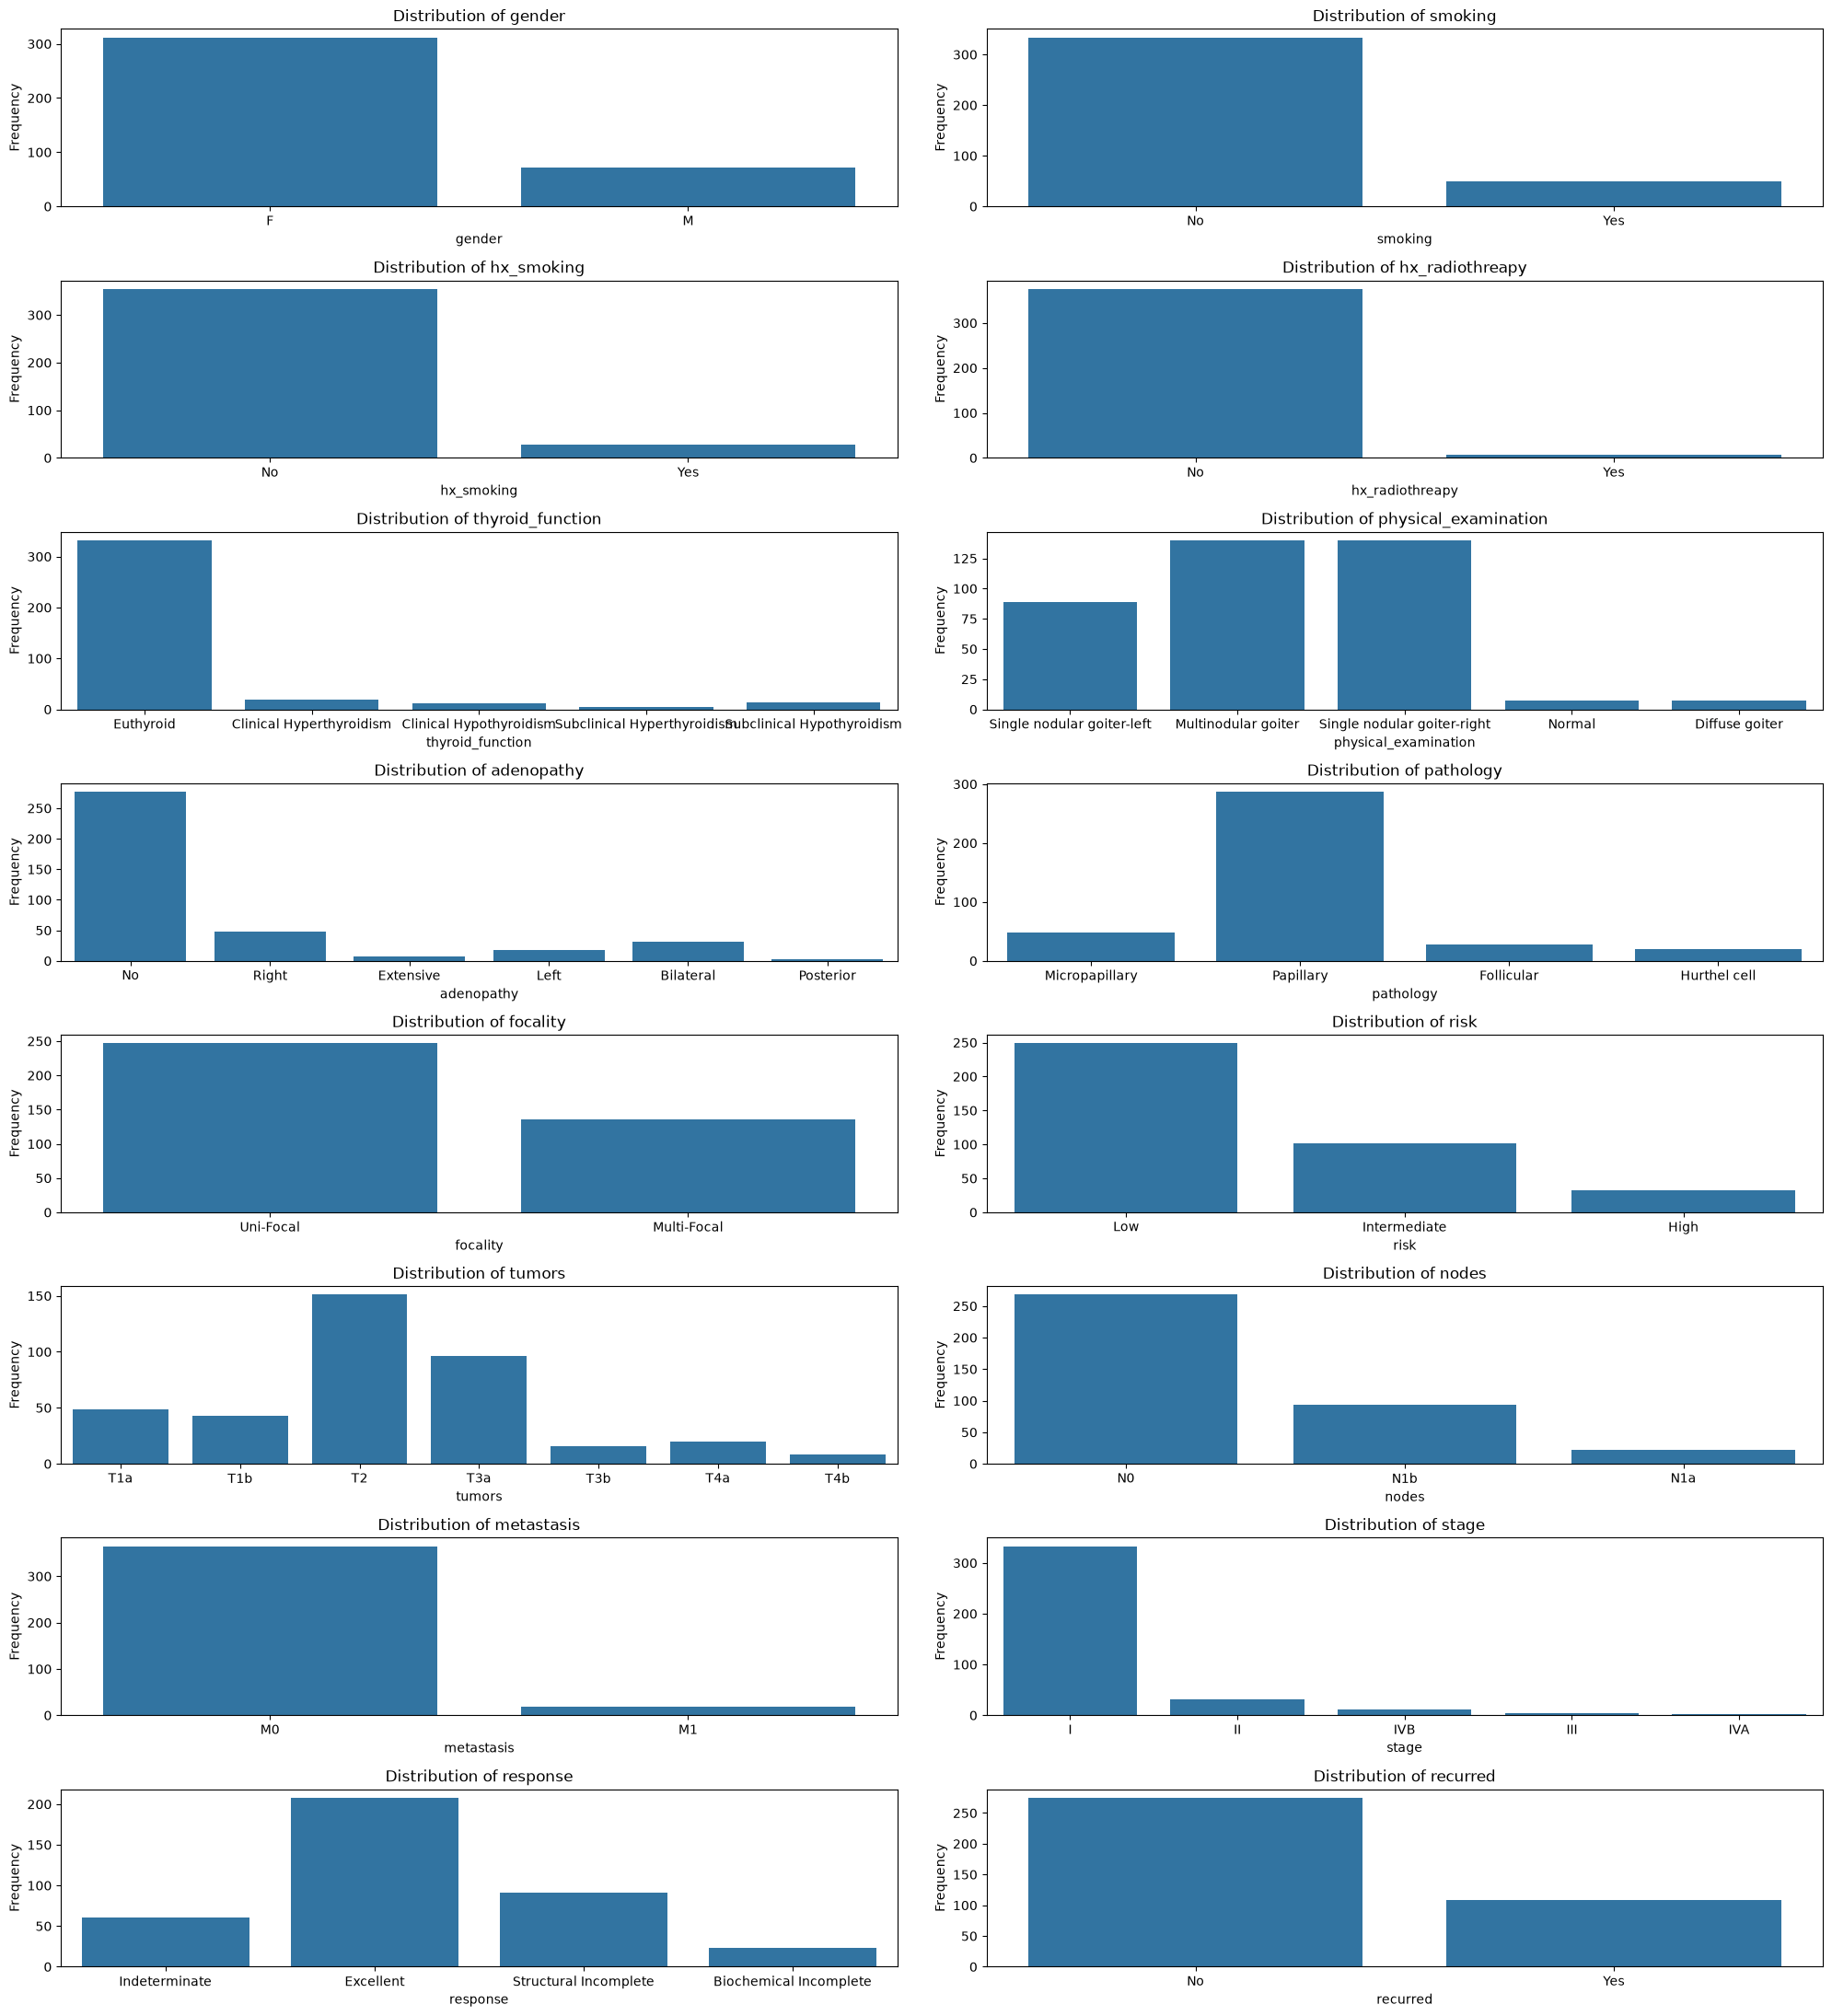

In [72]:
fig,axes = plt.subplots(figsize=(20,22),nrows=8,ncols=2)
axes = axes.flatten()
for index,col in enumerate(object_cols):
    sns.countplot(data=df,x=col,ax=axes[index])
    axes[index].set_title(f'Distribution of {col}')
    axes[index].set_xlabel(col)
    axes[index].set_ylabel('Frequency')
plt.tight_layout()
plt.show()

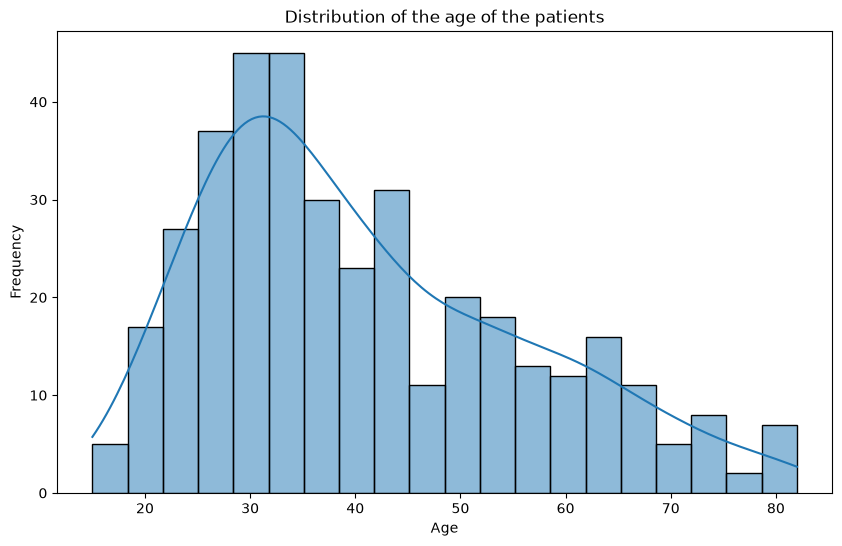

In [9]:
# Distribution of the age of the patients
fig,ax = plt.subplots(figsize=(10,6))
sns.histplot(data=df,x='Age',bins=20,kde=True)
plt.title('Distribution of the age of the patients')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


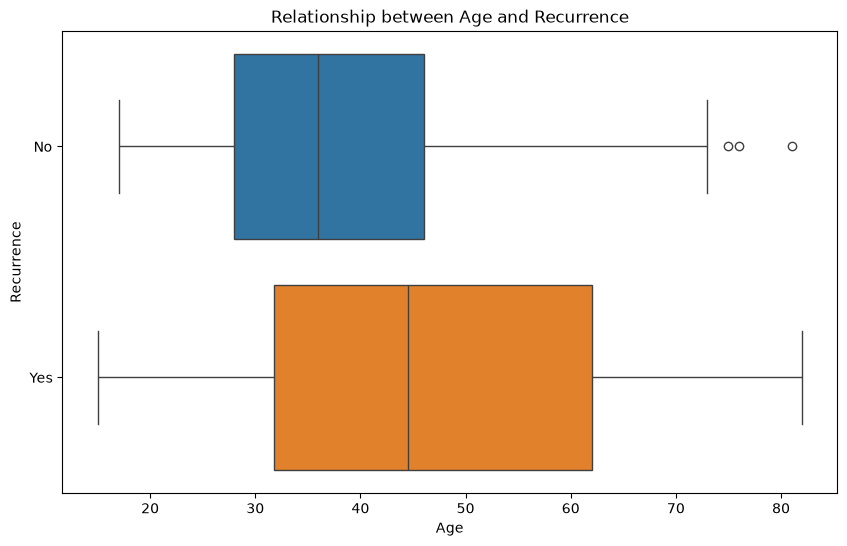

In [ ]:
# Relationship between Age and Recurrence
fig,ax = plt.subplots(figsize=(10,6))
sns.boxplot(data=df,x='age',y='recurred',hue='recurred')
plt.title('Relationship between Age and Recurrence')
plt.xlabel('Age')
plt.ylabel('Recurrence')
plt.show()

We can see that older people have higher recurrence rate.

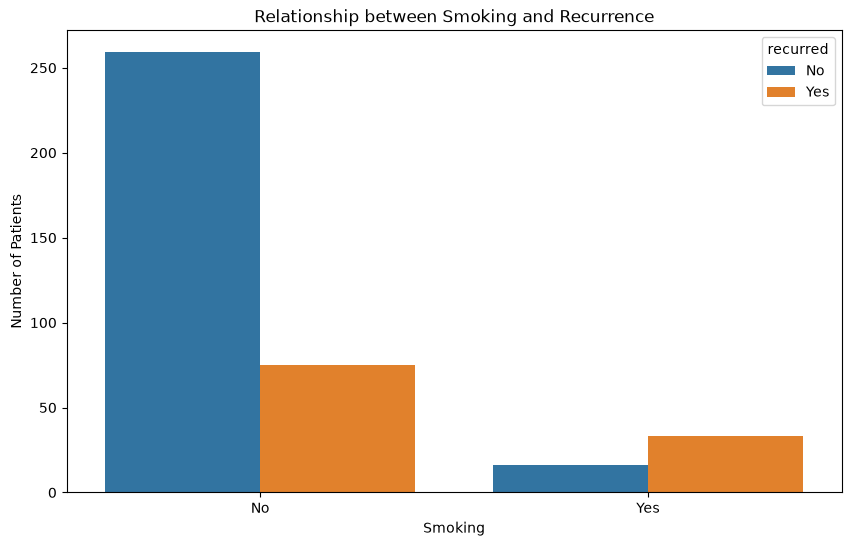

In [ ]:
# Relationship between smoking and recurrence
fig, ax = plt.subplots(figsize=(10, 6))

sns.countplot(
    data=df,
    x='smoking',
    hue='recurred',
    ax=ax
)
ax.set_title('Relationship between Smoking and Recurrence')
ax.set_xlabel('Smoking')
ax.set_ylabel('Number of Patients')

plt.show()